In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# 1. Análise Exploratória dos dados (EDA)

In [65]:
df = pd.read_csv(r"../../data/california.csv")

print("Foma do dataframe: ", df.shape)
df.head()

Foma do dataframe:  (20433, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129,322,126,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21,7099,1106,2401,1138,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52,1467,190,496,177,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52,1274,235,558,219,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52,1627,280,565,259,3.8462,342200.0,NEAR BAY


In [66]:
print("Colunas:")
df.columns

Colunas:


Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [67]:
print("Tipo dos dados:\n")
print(df.dtypes)

Tipo dos dados:

longitude             float64
latitude              float64
housing_median_age      int64
total_rooms             int64
total_bedrooms          int64
population              int64
households              int64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


In [68]:
print("Tipo de features cattegóricas: ")
df["ocean_proximity"].unique()

Tipo de features cattegóricas: 


<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

## 1.1 Distribuição das variáveis

Métricas de housing_median_age
  Média:          28.63
  Mediana:        29.00
  Moda:           52.00
  Desvio padrão:  12.59
  Skewness:       0.06
  Kurtosis:       -0.80


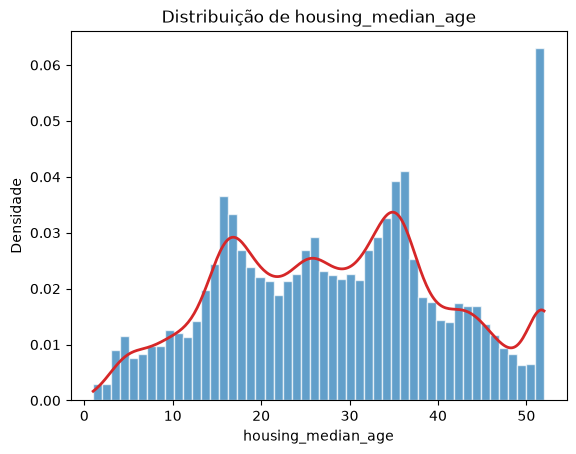

Métricas de median_income
  Média:          3.87
  Mediana:        3.54
  Moda:           3.12
  Desvio padrão:  1.90
  Skewness:       1.64
  Kurtosis:       4.94


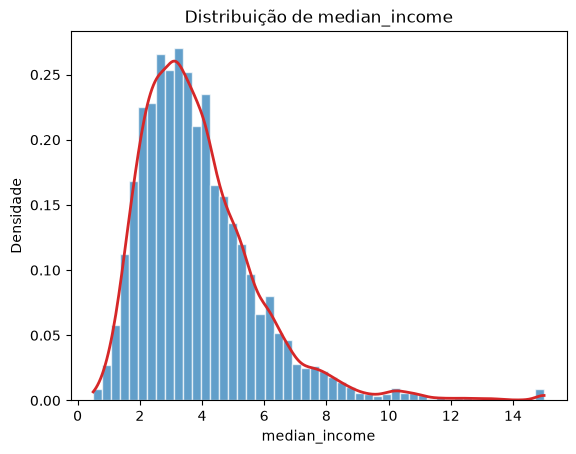

Métricas de total_rooms
  Média:          2636.50
  Mediana:        2127.00
  Moda:           1527.00
  Desvio padrão:  2185.27
  Skewness:       4.16
  Kurtosis:       32.71


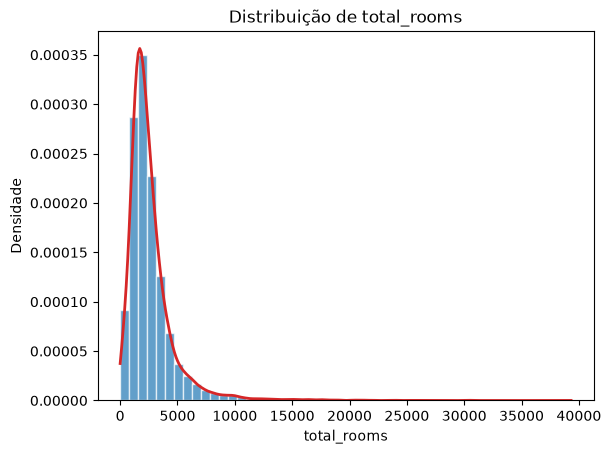

Métricas de total_bedrooms
  Média:          537.87
  Mediana:        435.00
  Moda:           280.00
  Desvio padrão:  421.39
  Skewness:       3.46
  Kurtosis:       21.99


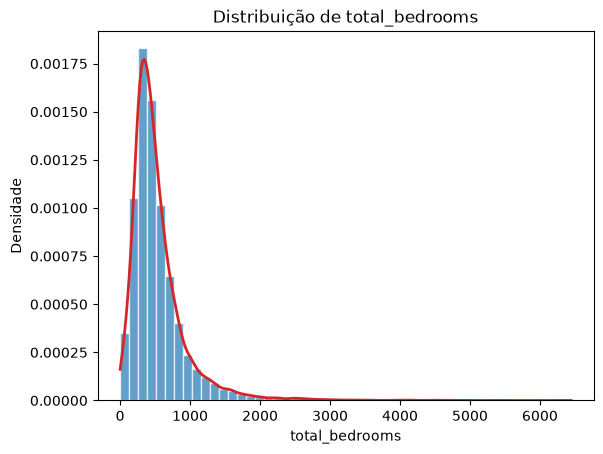

Métricas de population
  Média:          1424.95
  Mediana:        1166.00
  Moda:           891.00
  Desvio padrão:  1133.21
  Skewness:       4.96
  Kurtosis:       74.06


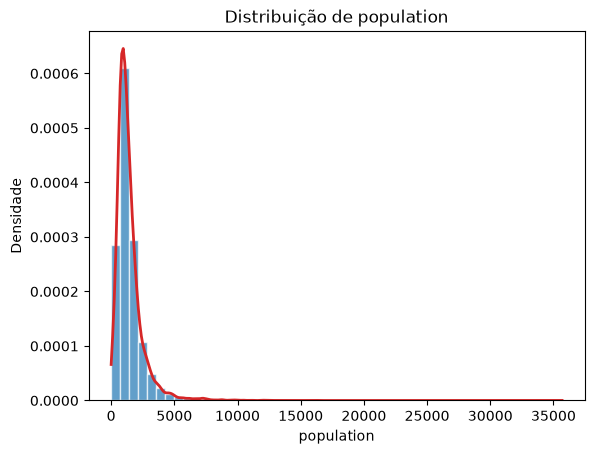

Métricas de households
  Média:          499.43
  Mediana:        409.00
  Moda:           306.00
  Desvio padrão:  382.30
  Skewness:       3.41
  Kurtosis:       22.09


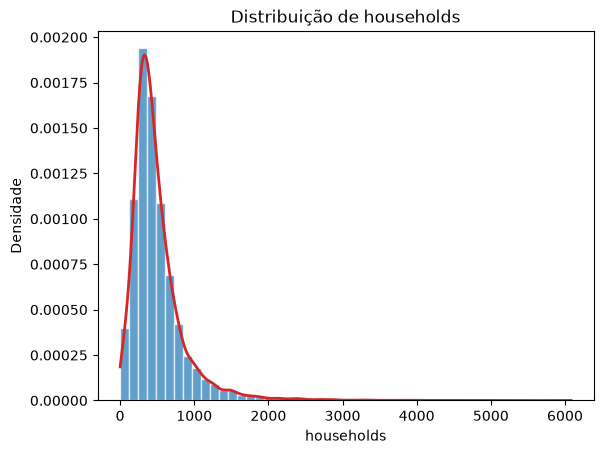

Métricas de median_house_value
  Média:          206864.41
  Mediana:        179700.00
  Moda:           500001.00
  Desvio padrão:  115435.67
  Skewness:       0.98
  Kurtosis:       0.33


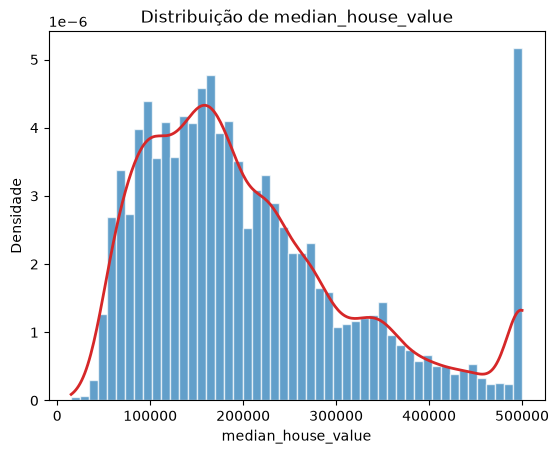

In [69]:
from scipy.stats import gaussian_kde

variaveis_numericas = ["housing_median_age", "median_income", "total_rooms", "total_bedrooms",
                       "population", "households", "median_house_value"]

# Variáveis numéricas: métricas descritivas + histogramas com curva de densidade (KDE)
for col in variaveis_numericas:
    valores = df[col]

    print(f"Métricas de {col}")
    print(f"  Média:          {valores.mean():.2f}")
    print(f"  Mediana:        {valores.median():.2f}")
    print(f"  Moda:           {valores.mode()[0]:.2f}")
    print(f"  Desvio padrão:  {valores.std():.2f}")
    print(f"  Skewness:       {valores.skew():.2f}")   # assimetria: > 0 cauda à direita, < 0 cauda à esquerda
    print(f"  Kurtosis:       {valores.kurt():.2f}")   # excesso de curtose: 0 = normal, > 0 caudas pesadas

    eixo_x = np.linspace(valores.min(), valores.max(), 300)

    plt.hist(valores, bins=50, density=True, edgecolor="white", alpha=0.7)
    plt.plot(eixo_x, gaussian_kde(valores)(eixo_x), color="tab:red", linewidth=2)

    plt.xlabel(col)
    plt.ylabel("Densidade")
    plt.title(f"Distribuição de {col}")
    plt.show()

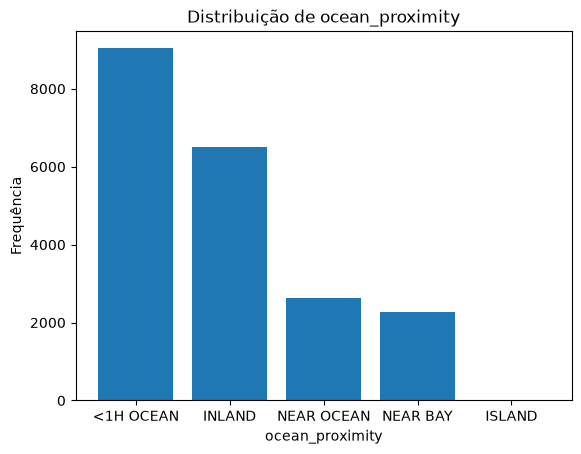

In [70]:
# Variável categórica: contagem por categoria
contagem = df["ocean_proximity"].value_counts()

plt.bar(contagem.index, contagem.values)
plt.xlabel("ocean_proximity")
plt.ylabel("Frequência")
plt.title("Distribuição de ocean_proximity")
plt.show()

### Conclusões da seção 1.1

**`housing_median_age`** é aproximadamente simétrica (média de 28,6 e mediana de 29 anos), com picos perto de 17 e 35 anos. O pico isolado em **52 anos** mostra que a variável foi, provavelmente, **truncada** (todos os distritos com 52 anos ou mais foram registrados como 52).

**`median_income`** é **assimétrica à direita** (média de 3,87 contra mediana de 3,54): a maioria dos distritos tem renda entre 2,6 e 4,7, com uma cauda longa de distritos ricos. Também há um pequeno acúmulo no teto de **15**.

**`total_rooms`, `total_bedrooms`, `population` e `households`** têm o mesmo formato: **fortemente assimétricas à direita**, com quase todos os distritos concentrados nos valores baixos e uma cauda muito longa.

| Variável | Mediana | Máximo | Skewness | Kurtosis |
| --- | --- | --- | --- | --- |
| `total_rooms` | 2.127 | 39.320 | 4,16 | 32,7 |
| `total_bedrooms` | 435 | 6.445 | 3,46 | 22,0 |
| `population` | 1.166 | 35.682 | 4,96 | 74,1 |
| `households` | 409 | 6.082 | 3,41 | 22,1 |

- A **kurtosis muito alta** (de 22 a 74) indica poucos distritos extremamente grandes: o máximo de `population` é cerca de 30 vezes a mediana. Por isso os histogramas parecem "espremidos" à esquerda.
- As quatro são **contagens totais por distrito**, então medem principalmente o **tamanho do distrito**, e não as características das casas. Elas são **muito correlacionadas entre si** (de 0,86 a 0,98; `total_bedrooms` × `households` = 0,98), o que significa que carregam quase a mesma informação.

**`median_house_value`** (o target) também é **assimétrica à direita**, concentrada entre US$ 120 mil e US$ 265 mil. O pico em **US$ 500.001** reúne **4,7% dos distritos**: o valor foi limitado na coleta, então esses imóveis valem "500 mil ou mais", e nenhum modelo conseguirá prever valores acima disso.

**`ocean_proximity`** é **desbalanceada**: `<1H OCEAN` (9.034) e `INLAND` (6.496) somam mais de 75% dos distritos, enquanto `ISLAND` tem **apenas 5 observações**. Na divisão 50/50 em treino e teste, essa categoria pode ficar inteira de um lado só.

## 1.2 Relação das variáveis com o preço dos imóveis (`median_house_value`)

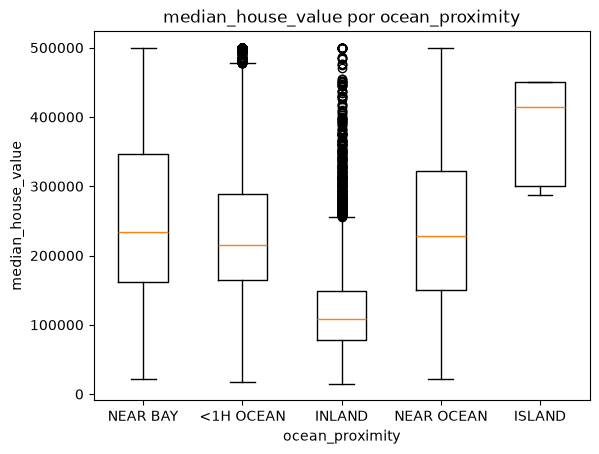

In [71]:
categorias = df["ocean_proximity"].unique()

plt.boxplot([df.loc[df["ocean_proximity"] == c, "median_house_value"] for c in categorias],
            tick_labels=categorias)
plt.xlabel("ocean_proximity")
plt.ylabel("median_house_value")
plt.title("median_house_value por ocean_proximity")
plt.show()

housing_median_age vs. median_house_value
  Correlação:  0.106
  Covariância: 154,704


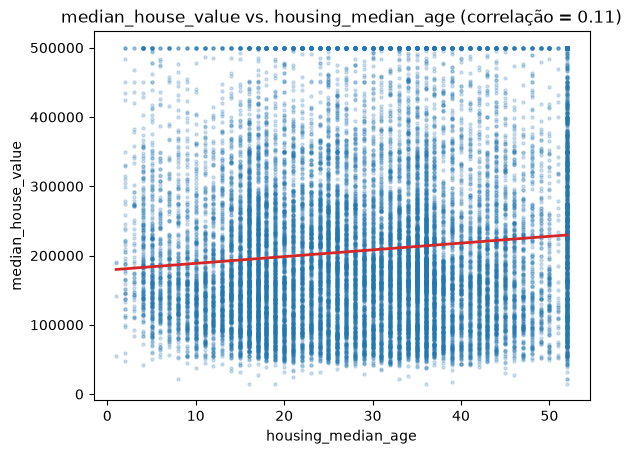

median_income vs. median_house_value
  Correlação:  0.688
  Covariância: 150,919


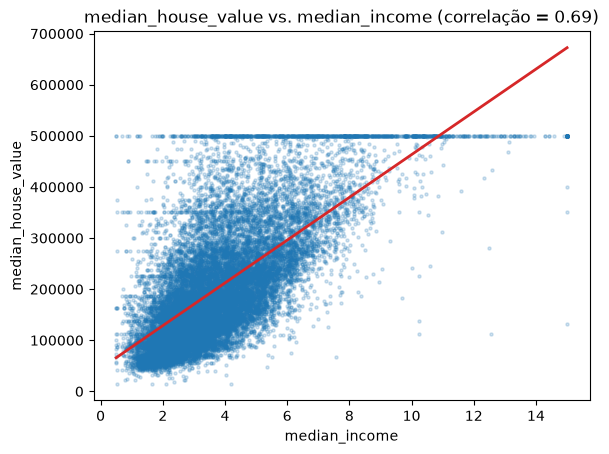

total_rooms vs. median_house_value
  Correlação:  0.133
  Covariância: 33,624,519


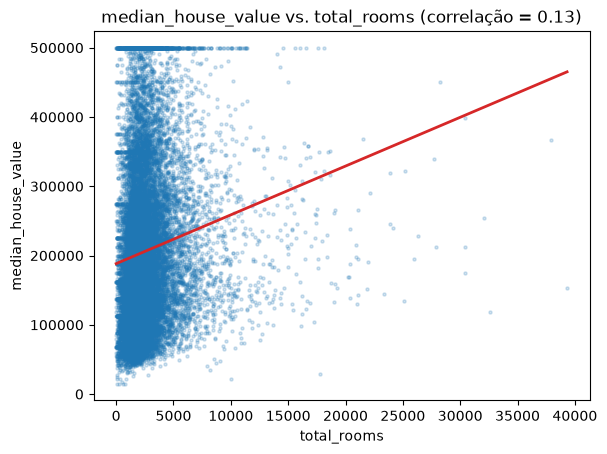

total_bedrooms vs. median_house_value
  Correlação:  0.050
  Covariância: 2,416,878


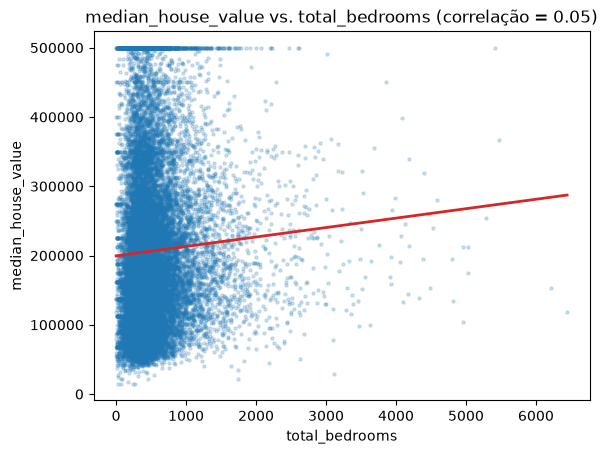

population vs. median_house_value
  Correlação:  -0.025
  Covariância: -3,309,526


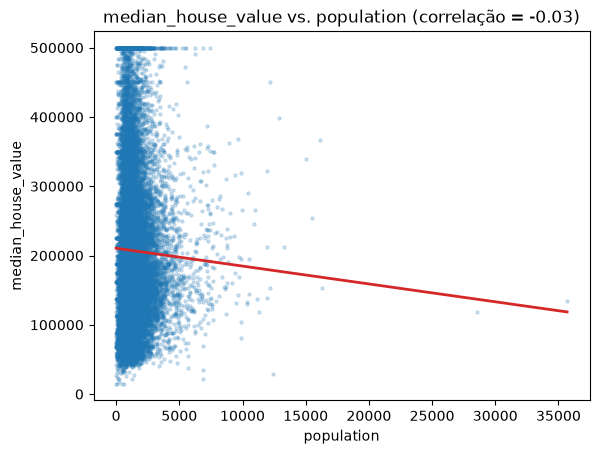

households vs. median_house_value
  Correlação:  0.065
  Covariância: 2,863,815


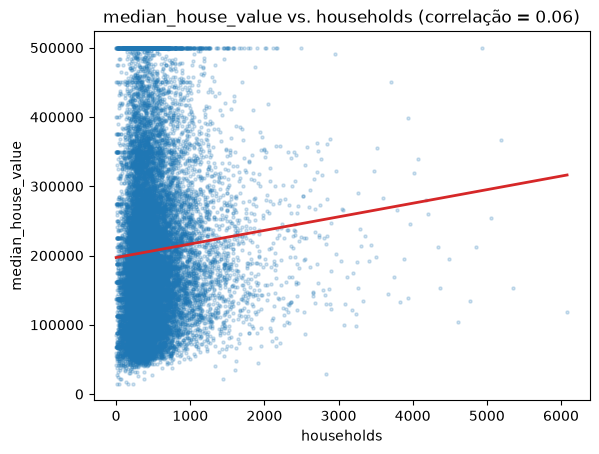

In [72]:
# Variáveis numéricas vs. target: dispersão com linha de tendência (reta de mínimos quadrados)
for col in ["housing_median_age", "median_income", "total_rooms", "total_bedrooms", "population", "households"]:
    x, y = df[col], df["median_house_value"]
    a, b = np.polyfit(x, y, 1)

    print(f"{col} vs. median_house_value")
    print(f"  Correlação:  {x.corr(y):.3f}")    # adimensional, entre -1 e 1: comparável entre variáveis
    print(f"  Covariância: {x.cov(y):,.0f}")    # depende das unidades de x e y: NÃO comparável entre variáveis

    plt.scatter(x, y, s=5, alpha=0.2)
    plt.plot(x.sort_values(), a * x.sort_values() + b, color="tab:red", linewidth=2)

    plt.xlabel(col)
    plt.ylabel("median_house_value")
    plt.title(f"median_house_value vs. {col} (correlação = {x.corr(y):.2f})")
    plt.show()

### Conclusões da seção 1.2

**`ocean_proximity` (box plot)**
- **A localização diferencia bem o preço.** Distritos `INLAND` (interior) são os mais baratos, com mediana de **US$ 108,7 mil**, menos da metade das categorias do litoral.
- **`<1H OCEAN`, `NEAR OCEAN` e `NEAR BAY` são parecidas**, com medianas entre US$ 215 mil e US$ 234 mil e caixas sobrepostas. A distinção relevante é "interior vs. litoral".
- **`INLAND` tem muitos outliers acima de US$ 255 mil**, então a localização sozinha não explica todo o preço. `ISLAND` tem a maior mediana (US$ 414,7 mil), mas com só 5 observações essa estimativa é pouco confiável.

**Variáveis numéricas (dispersão, correlação e covariância)**

| Variável | Correlação | Covariância |
| --- | --- | --- |
| `median_income` | **0,688** | 150.919 |
| `total_rooms` | 0,133 | **33.624.519** |
| `housing_median_age` | 0,106 | 154.704 |
| `households` | 0,065 | 2.863.815 |
| `total_bedrooms` | 0,050 | 2.416.878 |
| `population` | −0,025 | −3.309.526 |

**Correlação vs. covariância**
- As duas medem se `x` e `y` variam **juntas** e têm o **mesmo sinal**: positivo quando crescem juntas, negativo quando uma cresce e a outra cai. Só `population` tem sinal negativo, e mesmo assim muito fraco.
- A **covariância depende das unidades** das variáveis: $\text{cov}(x, y) = \text{corr}(x, y) \cdot s_x \cdot s_y$. Por isso ela **não serve para comparar variáveis**. A tabela mostra isso: `total_rooms` tem a **maior** covariância (33,6 milhões) só porque seus valores são enormes (desvio padrão de 2.185), embora a relação com o preço seja fraca. Já `median_income`, a variável mais associada ao preço, tem covariância **menor** que `housing_median_age`, porque a renda é medida em uma escala pequena (desvio padrão de 1,9).
- A **correlação** divide a covariância pelos desvios padrão, fica entre −1 e 1 e **não depende das unidades**. É ela que deve ser usada para comparar a força das relações.

**`median_income`**
- **É a variável mais associada ao preço** (correlação de **0,69**). A relação é clara e crescente: a mediana do preço sobe de US$ 93 mil para distritos com renda até 2 para US$ 336 mil com renda entre 6 e 8.
- **A reta de tendência ultrapassa o teto de US$ 500.001** a partir de renda ≈ 11. Acima disso, os pontos formam uma linha horizontal no teto: o truncamento do target "achata" a relação para as rendas mais altas, e uma regressão linear superestimaria esses preços.
- A dispersão vertical é grande para uma mesma renda, então outras variáveis, como a localização, ajudam a explicar o restante.

**`housing_median_age`**
- **Quase não tem relação linear com o preço** (correlação de **0,11**). Os pontos ocupam toda a faixa de preços para qualquer idade, e a linha de tendência é quase plana.
- A exceção é o grupo truncado em **52 anos**, com mediana de US$ 259 mil contra cerca de US$ 170 mil a US$ 185 mil nas outras faixas. Provavelmente são bairros antigos e centrais das grandes cidades. Esse efeito não é linear e tende a ser mais bem capturado por árvores.

**`total_rooms`, `total_bedrooms`, `population` e `households`**
- **Praticamente não têm relação com o preço**: as correlações ficam entre −0,03 e 0,13, apesar das covariâncias de milhões, que refletem só a escala das contagens. Os pontos formam uma "parede" vertical perto de zero, cobrindo toda a faixa de preços.
- As **linhas de tendência são enganosas**: a inclinação é definida por poucos distritos gigantes na cauda direita, e não pela massa de dados. É um exemplo de como outliers distorcem a regressão linear.
- Isso faz sentido: são contagens que medem o **tamanho** do distrito, e um distrito grande não é necessariamente caro. Para essas variáveis informarem algo sobre o preço, seria preciso transformá-las em **razões**, como cômodos por domicílio ou quartos por cômodo.

**Em todos os gráficos** aparece a faixa horizontal no teto de **US$ 500.001**, presente em todas as faixas de renda e idade. Isso reforça o efeito do truncamento visto na seção 1.1.